# Credit AI: reproducibilidad y lectura de resultados

**Edwin Montes-Orozco e Israel Cedillo-Lazcano**

Este notebook explora una ejecucion real de la reconstruccion completa del protocolo historico. Las particiones originales del paper no se recuperaron: las cifras incluidas aqui pertenecen a un nuevo split congelado. No son una certificacion de las cifras originales. Los experimentos HMDA y LendingClub siguen siendo trabajo futuro.

Puedes leer todas las salidas sin volver a entrenar; para entrenar utiliza la celda opcional al final.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if not (ROOT / 'config/protocol.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'config/protocol.json').exists(), 'Abre el notebook desde la carpeta del paquete o notebooks/'
sys.path.insert(0, str(ROOT / 'src'))
RUN = ROOT / 'results/reference_run'
manifest = json.loads((RUN / 'manifest.json').read_text())
print(manifest['status'])
print('Modelos:', manifest['fitted_models'], '| Explicaciones LIME:', manifest['lime_explanations'])
print('Versiones:', manifest['package_versions'])

PROTOCOL_RECONSTRUCTION_NOT_ORIGINAL_NUMERICAL_REPLICATION
Modelos: 45 | Explicaciones LIME: 60
Versiones: {'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'scikit-learn': '1.8.0', 'shap': '0.49.1', 'lime': '0.2.0.1', 'matplotlib': '3.10.8', 'joblib': '1.5.3'}


## 1. Datos y particiones

UCI usa `kredit=0` para malo y `1` para bueno; nuestro target es `Y=1-kredit`. Edad, estatus personal/sexo y trabajador extranjero no se usan como predictores. Edad se conserva exclusivamente para la auditoria. El split tiene fitting, calibracion, seleccion de politica y prueba, sin traslapes.

In [2]:
from credit_ai.core import load_data, validate_split
X, y, age, raw = load_data(ROOT / 'data/raw/SouthGermanCredit.asc')
split_file = json.loads((ROOT / 'config/frozen_split.json').read_text())
split = {k: np.asarray(v, dtype=int) for k, v in split_file['indices'].items()}
validate_split(split, y)
display(pd.DataFrame([{'partition': k, 'n': len(v), 'bad': int(y[v].sum()), 'good': int((1-y[v]).sum())} for k,v in split.items()]))
print('Predictores:', X.columns.tolist())
print('SHA-256 fuente:', split_file['source_sha256'])

Predictores: ['status', 'duration', 'credit_history', 'purpose', 'amount', 'savings', 'employment_duration', 'installment_rate', 'other_debtors', 'present_residence', 'property', 'other_installment_plans', 'housing', 'number_credits', 'job', 'people_liable', 'telephone']
SHA-256 fuente: 5f363343f356ca38a0236baab849e472846399b2176ccc5bd686483dd8a7562f


,partition,n,bad,good
0,fit,550,165,385
1,calibration,150,45,105
2,policy,100,30,70
3,test,200,60,140


## 2. Riesgo, decision y perdida

$g_i=p_iL_i-(1-p_i)\Pi_i$, y aprobamos cuando $p_i<\Pi_i/(L_i+\Pi_i)$. La politica U usa un umbral comun elegido en los 100 casos de politica; E usa un umbral economico por solicitante.

La perdida realizada usa la etiqueta del caso: aprobar bueno = margen negativo, aprobar malo = perdida positiva, rechazar = cero. La perdida esperada usa la probabilidad del modelo. Ninguna es rendimiento monetario observado.

In [3]:
table1 = pd.read_csv(RUN / 'table1_performance.csv')
display(table1)
print('Mejor AUROC medio:')
display(table1.query("policy == 'E'").sort_values('auroc', ascending=False).head(1))
print('Menor perdida del escenario:')
display(table1.sort_values('scenario_loss').head(1))

Mejor AUROC medio:
Menor perdida del escenario:


,model,weighting,policy,auroc,average_precision,brier,approval_pct,scenario_loss,loss_sd,model_expected_loss
0,GB,balanced,E,0.741583,0.570436,0.177372,21.3,-0.005946,0.007161,-0.015154
1,GB,balanced,U,0.741583,0.570436,0.177372,44.2,-0.001247,0.016765,-0.005260
2,GB,idcs,E,0.700512,0.507403,0.187537,19.9,0.013743,0.019410,-0.021653
3,GB,idcs,U,0.700512,0.507403,0.187537,35.2,0.017341,0.023521,-0.014236
4,GB,standard,E,0.752083,0.588895,0.174299,21.0,-0.012313,0.014566,-0.013548
5,GB,standard,U,0.752083,0.588895,0.174299,46.9,0.002478,0.035208,0.000717
6,LR,balanced,E,0.711786,0.532612,0.184224,22.3,-0.007457,0.009949,-0.017181
7,LR,balanced,U,0.711786,0.532612,0.184224,34.0,0.011055,0.016707,-0.005480
8,LR,idcs,E,0.689143,0.504135,0.190676,23.9,0.002810,0.016397,-0.022947
9,LR,idcs,U,0.689143,0.504135,0.190676,30.1,0.008903,0.012645,-0.008427


,model,weighting,policy,auroc,average_precision,brier,approval_pct,scenario_loss,loss_sd,model_expected_loss
16,RF,standard,E,0.770476,0.581125,0.183738,0.8,0.000471,0.006017,-0.000255


,model,weighting,policy,auroc,average_precision,brier,approval_pct,scenario_loss,loss_sd,model_expected_loss
4,GB,standard,E,0.752083,0.588895,0.174299,21.0,-0.012313,0.014566,-0.013548


## 3. Comparaciones con incertidumbre

Los intervalos de Tabla 2 remuestrean 200 diferencias pareadas, despues de promediar por caso los cinco bootstraps de entrenamiento. Son intervalos condicionales a este split y sus supuestos; no cubren cambio de poblacion ni incertidumbre de costos.

In [4]:
table2 = pd.read_csv(RUN / 'table2_loss_comparisons.csv')
table2['includes_zero'] = (table2.ci_low <= 0) & (table2.ci_high >= 0)
display(table2)

,model,weighting,policy,delta_loss,ci_low,ci_high,includes_zero
0,LR,standard,E,-0.007122,-0.021098,0.006626,True
1,LR,balanced,E,-0.013011,-0.027846,0.001629,True
2,LR,idcs,E,-0.002744,-0.022738,0.019314,True
3,RF,standard,E,-0.005083,-0.036738,0.023868,True
4,RF,balanced,E,-0.011855,-0.042413,0.016103,True
5,RF,idcs,E,-0.012615,-0.044660,0.020746,True
6,GB,standard,E,-0.017867,-0.047095,0.016820,True
7,GB,balanced,E,-0.011500,-0.041510,0.023026,True
8,GB,idcs,E,0.008189,-0.017374,0.042346,True


## 4. Explicaciones de riesgo y determinantes de politica

SHAP explica el **logit calibrado**, con contribuciones agrupadas por variable original. Se comprueba aditividad; esto no valida causalidad ni suficiencia legal. El margen y la perdida aparecen por separado: $D_i=\operatorname{logit}(p_i)+\log L_i-\log\Pi_i$. Rechazamos si $D_i\geq0$.

Overlap es Jaccard de hasta tres factores positivos, sobre pares con igual accion o denegacion conjunta. Los conjuntos vacios producen valores indefinidos. Los denominadores se muestran.

Error maximo de aditividad agrupada: 4.884981308350689e-15


,model,weighting,same_action_overlap,joint_denial_overlap,flip_rate,all_pair_count,same_action_count,same_action_valid_overlap_count,joint_denial_count,joint_denial_valid_overlap_count,undefined_overlap_count
0,LR,standard,0.512916,0.520283,0.129,2000,1742,1742,1415,1415,0
1,LR,balanced,0.479095,0.495095,0.127,2000,1746,1746,1427,1427,0
2,LR,idcs,0.458641,0.447050,0.132,2000,1736,1736,1390,1390,0
3,RF,standard,0.534195,0.534551,0.013,2000,1974,1974,1971,1971,0
4,RF,balanced,0.537843,0.540932,0.041,2000,1918,1918,1893,1893,0
5,RF,idcs,0.482213,0.487147,0.053,2000,1894,1890,1831,1827,4
6,GB,standard,0.561973,0.586890,0.146,2000,1708,1708,1434,1434,0
7,GB,balanced,0.576291,0.603086,0.148,2000,1704,1704,1426,1426,0
8,GB,idcs,0.411775,0.435453,0.155,2000,1690,1690,1447,1447,0


,row_id,prob_bad,tau,margin,loss_bad,expected_approval_loss,policy_D,positive_top3_risk_factors
600,776,0.329313,0.154022,0.217957,1.197141,0.248054,0.992102,savings|status|duration
601,272,0.243639,0.091952,0.022905,0.226196,0.037785,1.157197,housing|amount|credit_history
602,726,0.260794,0.161123,0.152252,0.792692,0.094184,0.608053,other_installment_plans|purpose|duration
603,924,0.407098,0.162717,0.186840,0.961413,0.280611,1.262177,status|savings|job
604,432,0.234508,0.139384,0.108667,0.670957,0.074160,0.637381,other_installment_plans|status|property


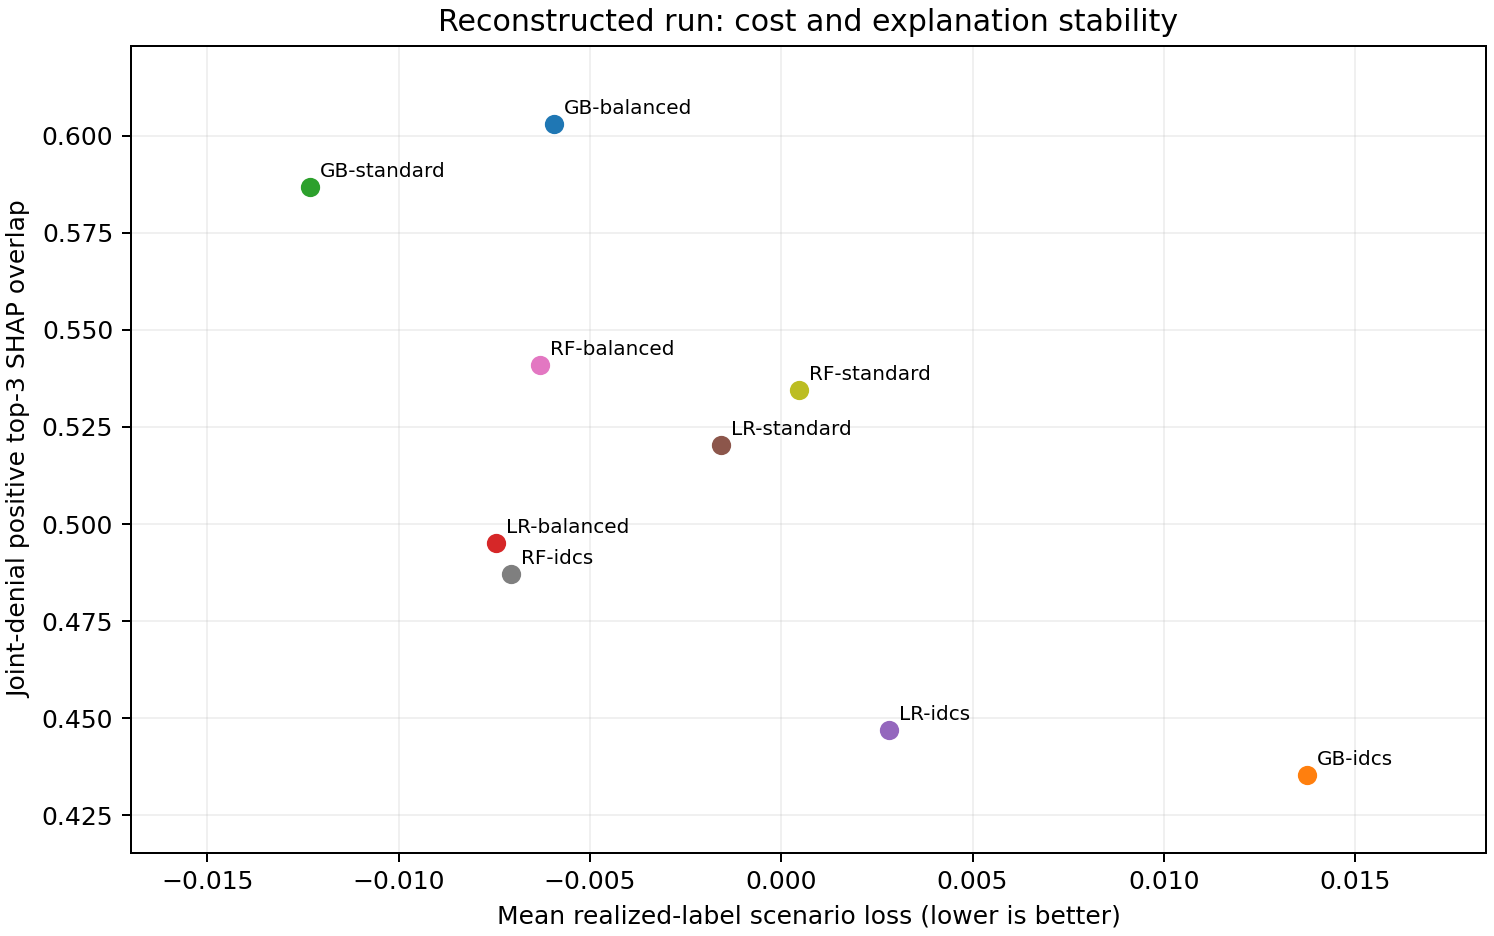

In [5]:
display(pd.read_csv(RUN / 'table3_explanation_stability.csv'))
checks = pd.read_csv(RUN / 'additivity_checks.csv')
print('Error maximo de aditividad agrupada:', checks.calibrated_grouped_additivity_max_error.max())
dossiers = pd.read_csv(RUN / 'decision_dossiers.csv')
display(dossiers.query("model == 'RF' and weighting == 'standard' and seed == 11")[['row_id','prob_bad','tau','margin','loss_bad','expected_approval_loss','policy_D','positive_top3_risk_factors']].head())
display(Image(filename=str(RUN / 'figures/figure1_cost_stability.png')))

## 5. LIME

Se usan 20 casos fijos, tres semillas del explicador y 1,500 muestras por vecindario. LIME explica probabilidad calibrada; SHAP explica logit calibrado. El R2 es ajuste ponderado dentro del vecindario. Overlap entre metodos y entre semillas es descriptivo.

In [6]:
display(pd.Series(json.loads((RUN / 'lime_summary.json').read_text()), name='value').to_frame())
display(pd.read_csv(RUN / 'lime_explanations.csv').head(6))

,value
weighted_neighborhood_r2,0.482729
explainer_seed_overlap,0.643333
cross_method_overlap,0.521667
explanation_count,60
record_count,20
valid_seed_overlap_pairs,60
valid_cross_method_overlap_count,60
output_object,LIME: calibrated bad-credit probability; SHAP:...


,row_id,explainer_seed,weighted_neighborhood_r2,positive_top3,shap_positive_top3,cross_method_overlap,local_prediction,calibrated_prob_bad,lime_intercept,num_samples
0,432,101,0.135275,status|property|duration,other_installment_plans|status|property,0.5,0.286986,0.234508,0.292983,1500
1,51,101,0.222385,savings|duration|credit_history,savings|duration|job,0.5,0.294568,0.279168,0.294455,1500
2,760,101,0.243739,savings|credit_history|status,duration|savings|status,0.5,0.324821,0.330456,0.272017,1500
3,267,101,0.575381,duration|credit_history|purpose,amount|purpose|property,0.2,0.264344,0.261940,0.355052,1500
4,69,101,0.626577,savings|property|duration,savings|housing|duration,0.5,0.295235,0.291372,0.294380,1500
5,536,101,0.680596,savings|purpose|duration,purpose|savings|people_liable,0.5,0.204110,0.204262,0.336678,1500


## 6. Revision humana hipotetica

Las rutas usan solo scores, umbrales y explicaciones. Las etiquetas se usan despues, para evaluar. El escenario imperfecto corrige 50% de las acciones incorrectas e introduce error en 5% de las correctas, con costo 0.01 por caso revisado. La cota oraculo no representa rendimiento humano observado. Sin mejora, toda ruta aumenta la perdida en 0.01 veces el presupuesto.

Verificacion de costo de revision sin mejora: OK


,routing,budget,baseline_loss,reviewed_loss,delta_loss
0,random,0.05,-0.004399,-0.006021,-0.001622
1,uncertainty,0.05,-0.004399,-0.007648,-0.003250
2,instability,0.05,-0.004399,-0.004853,-0.000455
3,combined,0.05,-0.004399,-0.009296,-0.004898
4,random,0.10,-0.004399,-0.007643,-0.003244
5,uncertainty,0.10,-0.004399,-0.012291,-0.007892
6,instability,0.10,-0.004399,-0.009135,-0.004736
7,combined,0.10,-0.004399,-0.010530,-0.006131
8,random,0.20,-0.004399,-0.010887,-0.006488
9,uncertainty,0.20,-0.004399,-0.020083,-0.015684


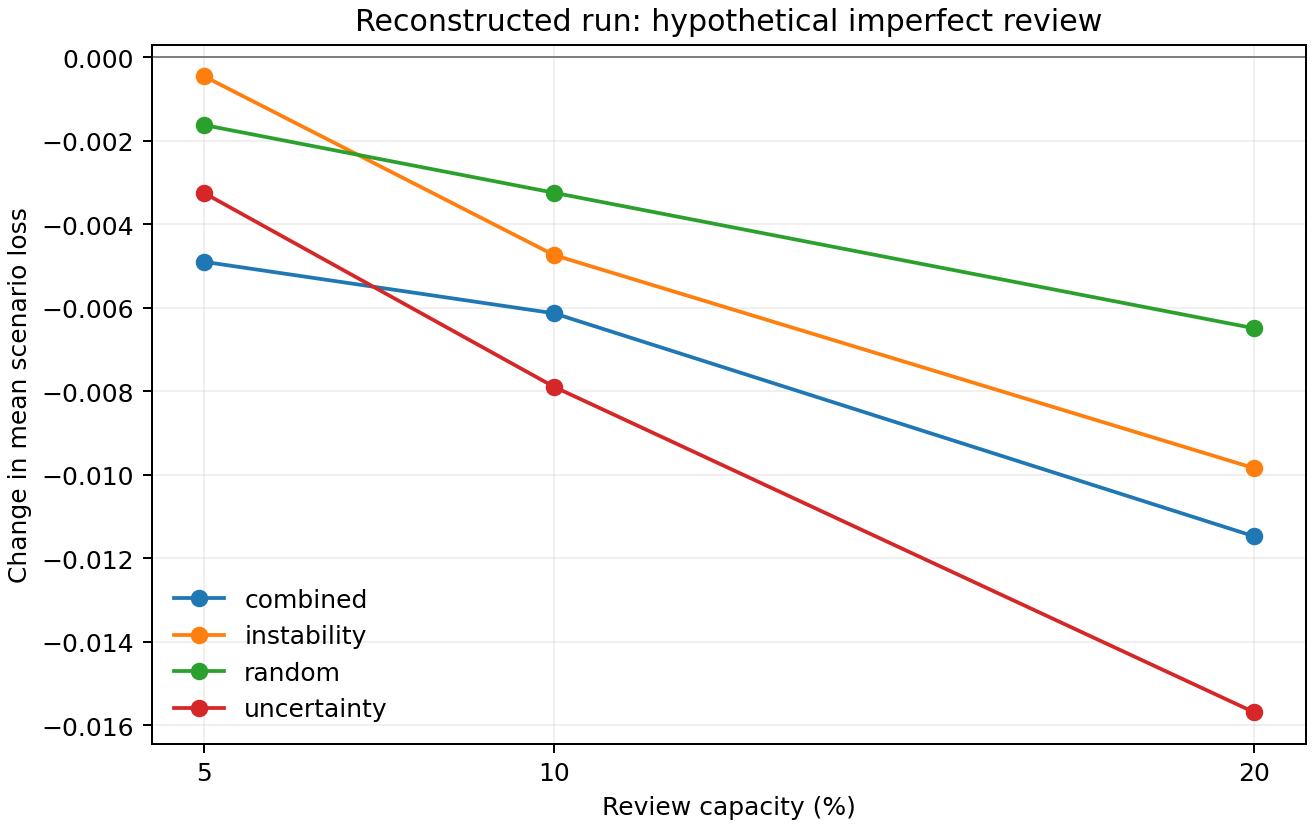

In [7]:
display(pd.read_csv(RUN / 'table4_imperfect_review.csv')[['routing','budget','baseline_loss','reviewed_loss','delta_loss']])
all_review = pd.read_csv(RUN / 'review_all_scenarios.csv')
none = all_review.query("scenario == 'no_improvement'")
assert np.allclose(none.delta_loss, none.budget * .01)
print('Verificacion de costo de revision sin mejora: OK')
display(Image(filename=str(RUN / 'figures/figure2_imperfect_review.png')))

## 7. Sensibilidad y auditoria por edad

Se cambian los costos con el ensamble fijo, sin volver a entrenar. BA = aprobacion entre malos; GR = rechazo entre buenos. Los grupos pequenos y el sesgo de seleccion impiden interpretar estas tasas como demostracion de discriminacion ilegal.

In [8]:
display(pd.read_csv(RUN / 'table5_cost_sensitivity.csv'))
display(pd.read_csv(RUN / 'table6_age_audit.csv'))

,loss_coefficient,margin_multiplier,approval_pct,scenario_loss,models_retrained
0,0.3,0.5,0.0,0.000000,False
1,0.3,1.0,31.0,-0.031209,False
2,0.3,1.5,64.0,-0.041517,False
3,0.6,0.5,0.0,0.000000,False
4,0.6,1.0,1.0,-0.004399,False
5,0.6,1.5,15.5,-0.029755,False
6,0.9,0.5,0.0,0.000000,False
7,0.9,1.0,0.0,0.000000,False
8,0.9,1.5,1.0,-0.006598,False


,age_group,n,bad_n,good_n,approval_n,bad_approval_n,good_rejection_n,approval_pct,bad_approval_pct,good_rejection_pct
0,age <25,31,13,18,0,0,18,0.000000,0.0,100.000000
1,age >=25,169,47,122,2,0,120,1.183432,0.0,98.360656


## 8. Comparacion con el manuscrito original

Estos numeros se transcribieron del PDF solo para comparar. Nunca se usan para construir predicciones ni graficas. Las coincidencias aisladas por redondeo no demuestran que se recupero la ejecucion original. Antes de enviar el paper como reproducible, hay que recuperar esa ejecucion o actualizar tablas, figuras y narrativa con una ejecucion verificable.

In [9]:
comparison = pd.read_csv(RUN / 'manuscript_comparison.csv')
print('Coinciden al redondeo publicado:', int(comparison.matches_reported_rounding.sum()), '/', len(comparison))
display(comparison.groupby('table', sort=False).agg(entries=('metric','size'), rounded_matches=('matches_reported_rounding','sum')))
display(comparison.query("matches_reported_rounding == False").head(12))

Coinciden al redondeo publicado: 4 / 203


,entries,rounded_matches
table,,
Table 1,108,1
Table 2,27,1
Table 3,27,0
Table 4,12,0
Table 5,18,0
Table 6,8,1
Section 6.2 LIME,3,1


,table,configuration,metric,reported,reconstructed,difference,rounding_tolerance,matches_reported_rounding
0,Table 1,GB / idcs / E,auroc,0.7510,0.700512,-0.050488,0.00050,False
1,Table 1,GB / idcs / E,average_precision,0.5740,0.507403,-0.066597,0.00050,False
2,Table 1,GB / idcs / E,brier,0.1750,0.187537,0.012537,0.00050,False
3,Table 1,GB / idcs / E,approval_pct,32.4000,19.900000,-12.500000,0.05000,False
4,Table 1,GB / idcs / E,scenario_loss,-0.0068,0.013743,0.020543,0.00005,False
5,Table 1,GB / idcs / E,loss_sd,0.0158,0.019410,0.003610,0.00005,False
6,Table 1,GB / idcs / U,auroc,0.7510,0.700512,-0.050488,0.00050,False
7,Table 1,GB / idcs / U,average_precision,0.5740,0.507403,-0.066597,0.00050,False
8,Table 1,GB / idcs / U,brier,0.1750,0.187537,0.012537,0.00050,False
9,Table 1,GB / idcs / U,approval_pct,24.6000,35.200000,10.600000,0.05000,False


## 9. Ejecutar nuevamente (opcional)

La celda no entrena por defecto. Cambia `RERUN=True` y elige una carpeta nueva. El script protege las carpetas de resultados existentes. Para comparar dos ejecuciones: `python compare_runs.py results/reference_run results/notebook_run`.

In [10]:
import subprocess
RERUN = False
if RERUN:
    subprocess.run([sys.executable, str(ROOT / 'run_experiments.py'), '--out', str(ROOT / 'results/notebook_run')], check=True, cwd=ROOT)
else:
    print('Para entrenar: python run_experiments.py --out results/my_run')

Para entrenar: python run_experiments.py --out results/my_run
